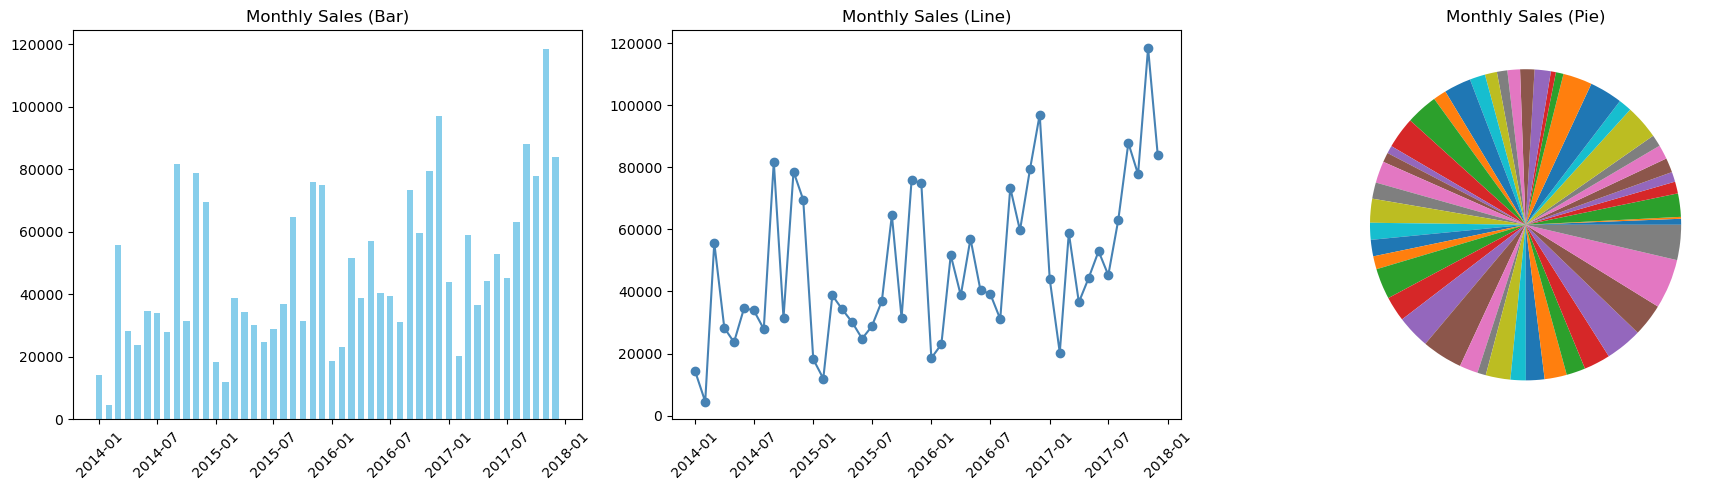

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgb

df = pd.read_csv("Sample - Superstore.csv", encoding='windows-1252')
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Month_Year'] = df['Order Date'].dt.to_period('M')

# Task 1
monthly_sales = df.groupby('Month_Year')['Sales'].sum().reset_index()
monthly_sales['Month_Year'] = monthly_sales['Month_Year'].dt.to_timestamp()

fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5))
# Bar
axes1[0].bar(monthly_sales['Month_Year'], monthly_sales['Sales'], width=20, color='skyblue')
axes1[0].set_title('Monthly Sales (Bar)')
axes1[0].tick_params(axis='x', rotation=45)
# Line
axes1[1].plot(monthly_sales['Month_Year'], monthly_sales['Sales'], marker='o', color='steelblue')
axes1[1].set_title('Monthly Sales (Line)')
axes1[1].tick_params(axis='x', rotation=45)
# Pie
axes1[2].pie(monthly_sales['Sales'], labels=None)
axes1[2].set_title('Monthly Sales (Pie)')
plt.tight_layout()
plt.show()



### 1. The line chart shows the trend best because it connects data points sequentially, making it visually intuitive to track continuous trends over time.
### 2. The pie chart completely hides the trend because judging the differences between many slices is visually difficult.

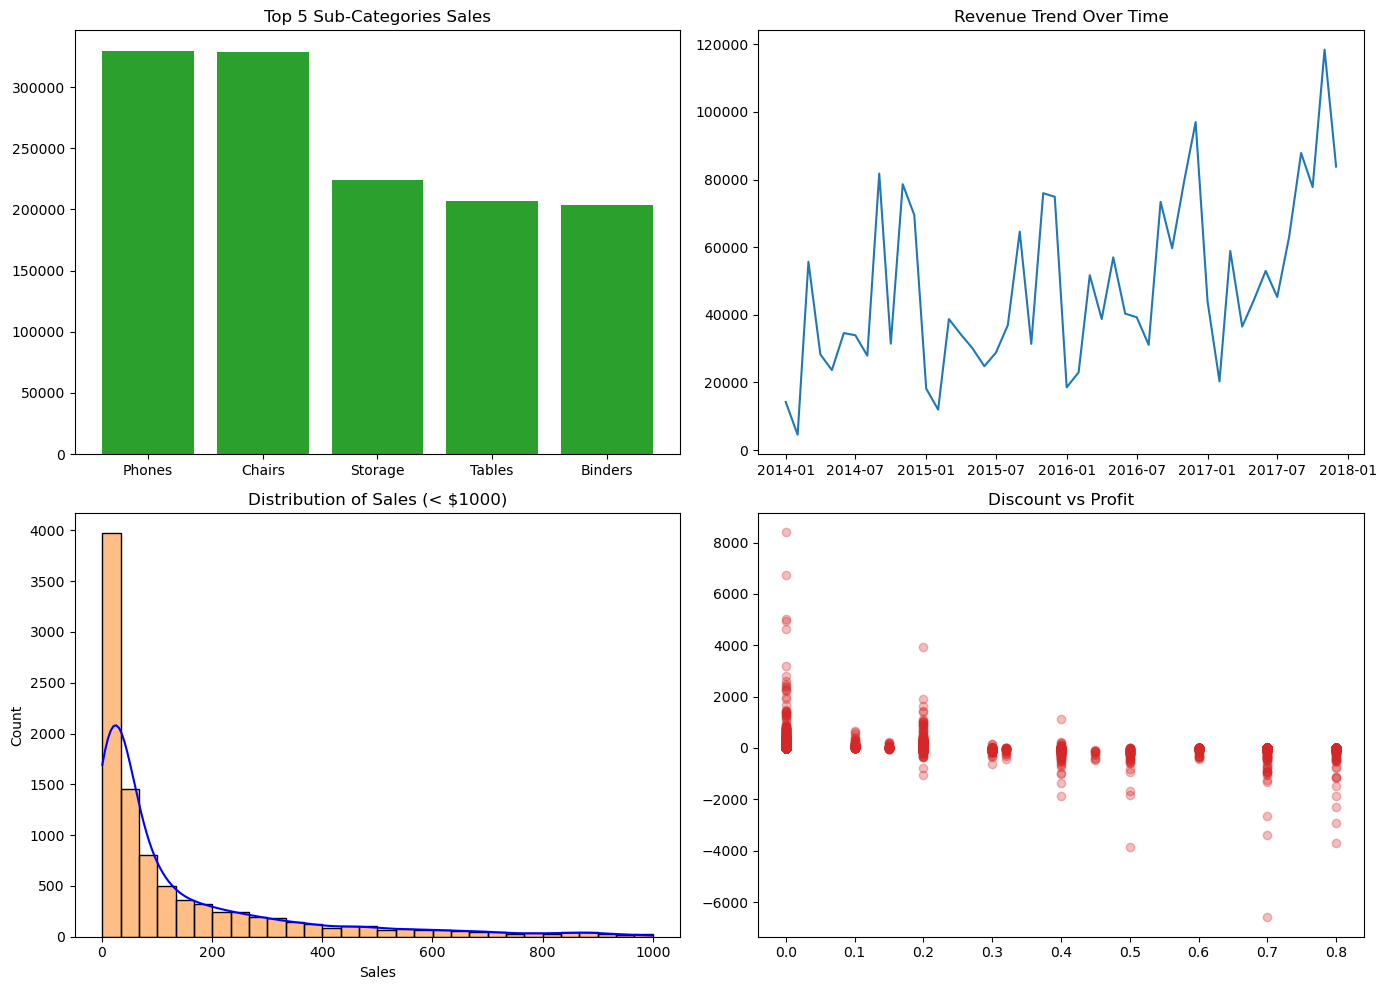

In [23]:
# Task 2 
fig2, axes2 = plt.subplots(2, 2, figsize=(14, 10))

# Top 5 sub-categories
top5_sub = df.groupby('Sub-Category')['Sales'].sum().nlargest(5).reset_index()
axes2[0, 0].bar(top5_sub['Sub-Category'], top5_sub['Sales'], color='#2ca02c')
axes2[0, 0].set_title('Top 5 Sub-Categories Sales')

# Trend over time (Line)
axes2[0, 1].plot(monthly_sales['Month_Year'], monthly_sales['Sales'], color='#1f77b4')
axes2[0, 1].set_title('Revenue Trend Over Time')

# Distribution of sales (filtered < 1000 for visibility)
sales_data = df[df['Sales'] < 1000]['Sales']

# 1. Plot both the bars and the smooth line on the specific axis
sns.histplot(sales_data, bins=30, color='#ff7f0e', edgecolor='black', kde=True, ax=axes2[1, 0])

# 2. change the lines color to blue
axes2[1, 0].lines[0].set_color('blue')

# 3. Set the title
axes2[1, 0].set_title('Distribution of Sales (< $1000)')
# Relationship Discount vs Profit
axes2[1, 1].scatter(df['Discount'], df['Profit'], alpha=0.3, color='#d62728')
axes2[1, 1].set_title('Discount vs Profit')

plt.tight_layout()
plt.show()

### 1. A bar chart fits best because it is designed for comparing discrete categories. A pie chart would underperform because precise value comparison across slices is difficult.
### 2. A line chart fits best because it clearly maps continuous sequential trends over time. A bar chart is a weak choice because rendering dozens of individual data points (months) clutters the axis and obscures the continuous trend.
### 3. A histogram fits best because it groups raw continuous data into bins to reveal spread and concentration. A bar chart of averages is misleading because it completely hides the distribution and individual outliers.
### 4. A scatter plot fits best because it highlights the correlation between two independent numeric variables. A line chart would mislead by falsely implying a continuous, connected sequence between independent orders.

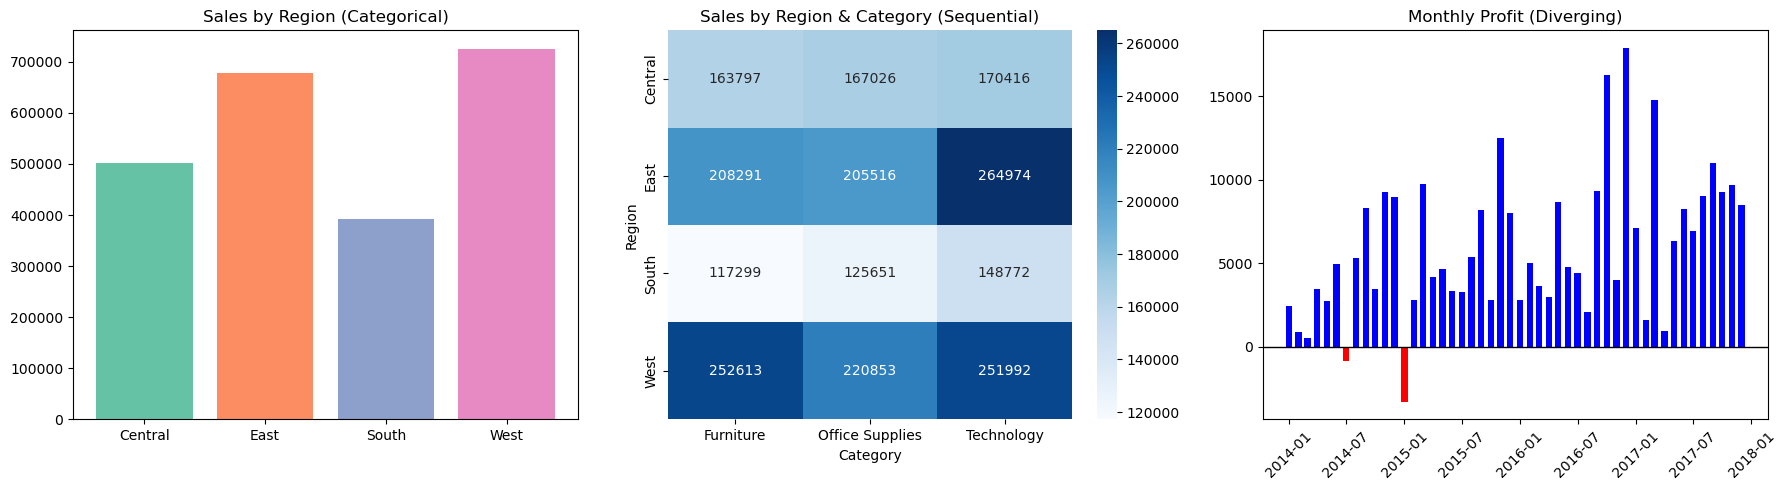

In [24]:
# Task 3 
fig3, axes3 = plt.subplots(1, 3, figsize=(18, 5))

# Categorical Palette
region_sales = df.groupby('Region')['Sales'].sum().reset_index()
cat_colors = sns.color_palette("Set2", len(region_sales))
axes3[0].bar(region_sales['Region'], region_sales['Sales'], color=cat_colors)
axes3[0].set_title('Sales by Region (Categorical)')

# Sequential Heatmap
reg_cat = df.groupby(['Region', 'Category'])['Sales'].sum().unstack()
sns.heatmap(reg_cat, cmap='Blues', ax=axes3[1], annot=True, fmt=".0f")
axes3[1].set_title('Sales by Region & Category (Sequential)')

# Diverging Profit
monthly_profit = df.groupby('Month_Year')['Profit'].sum().reset_index()
monthly_profit['Month_Year'] = monthly_profit['Month_Year'].dt.to_timestamp()
colors = ['red' if x < 0 else 'blue' for x in monthly_profit['Profit']]
axes3[2].bar(monthly_profit['Month_Year'], monthly_profit['Profit'], width=20, color=colors)
axes3[2].axhline(0, color='black', linewidth=1)
axes3[2].set_title('Monthly Profit (Diverging)')
axes3[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


 colors contrast ratios against white:
#66c2a5: 2.14 (Pass AA? False)
#fc8d62: 2.30 (Pass AA? False)
#8da0cb: 2.62 (Pass AA? False)
#e78ac3: 2.38 (Pass AA? False)


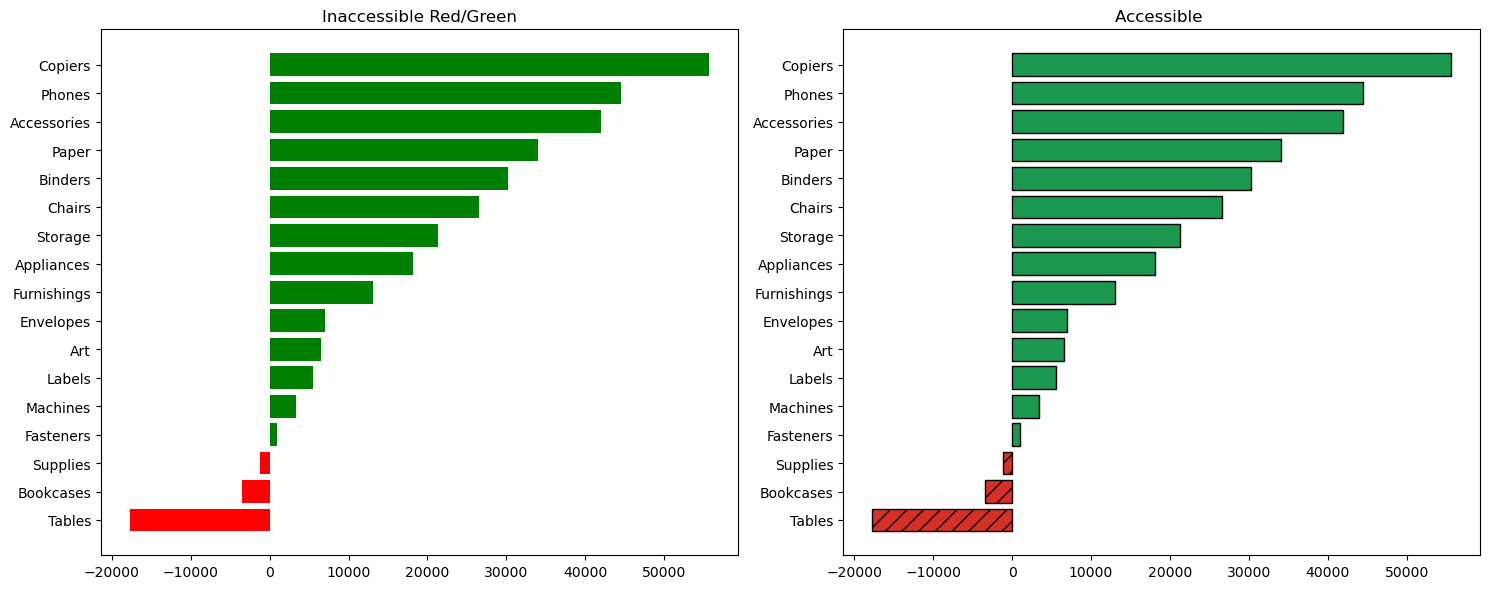

In [27]:
# Task 4 

# Contrast Ratio Calculation
def get_luminance(hex_color):
    rgb = to_rgb(hex_color)
    rgb_c = [c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4 for c in rgb]
    return 0.2126 * rgb_c[0] + 0.7152 * rgb_c[1] + 0.0722 * rgb_c[2]

def contrast_ratio(color1, color2):
    l1 = get_luminance(color1)
    l2 = get_luminance(color2)
    bright, dark = max(l1, l2), min(l1, l2)
    return (bright + 0.05) / (dark + 0.05)

bg_color = '#ffffff'
hex_cat_colors = cat_colors.as_hex()
print(" colors contrast ratios against white:")
for c in hex_cat_colors:
    r = contrast_ratio(c, bg_color)
    print(f"{c}: {r:.2f} (Pass AA? {r >= 4.5})")

# Sub-category Profit Chart 
sub_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values().reset_index()
fig4, ax4 = plt.subplots(1, 2, figsize=(15, 6))

# Original Red/Green 
rg_colors = ['red' if p < 0 else 'green' for p in sub_profit['Profit']]
ax4[0].barh(sub_profit['Sub-Category'], sub_profit['Profit'], color=rg_colors)
ax4[0].set_title('Inaccessible Red/Green')

# Fixed with Hatching and safer contrast colors
safe_colors = ['#d73027' if p < 0 else '#1a9850' for p in sub_profit['Profit']] 
hatches = ['//' if p < 0 else '' for p in sub_profit['Profit']]
bars = ax4[1].barh(sub_profit['Sub-Category'], sub_profit['Profit'], color=safe_colors, edgecolor='black')
for bar, h in zip(bars, hatches):
    bar.set_hatch(h)
ax4[1].set_title('Accessible ')

plt.tight_layout()
plt.show()


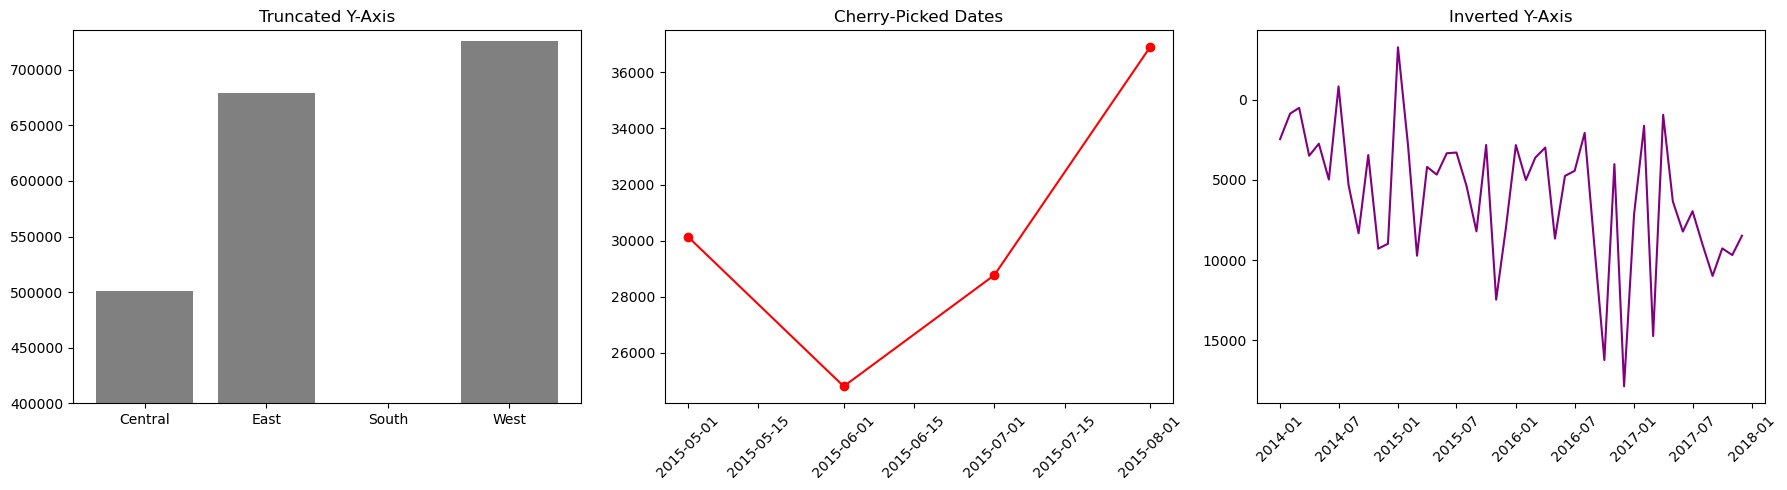

'role="img" aria-label="A horizontal bar chart showing Sub-Category profits, where profitable categories are solid green and loss-making categories are red with diagonal hatching to ensure readability for colorblind users.'

In [14]:
# Task 5 
fig5, axes5 = plt.subplots(1, 3, figsize=(18, 5))

# Region sales
axes5[0].bar(region_sales['Region'], region_sales['Sales'], color='gray')
axes5[0].set_ylim(400000, region_sales['Sales'].max() + 10000)
axes5[0].set_title('Truncated Y-Axis')

# Cherry-picked date window
cherry_df = monthly_sales[(monthly_sales['Month_Year'] >= '2015-05-01') & (monthly_sales['Month_Year'] <= '2015-08-01')]
axes5[1].plot(cherry_df['Month_Year'], cherry_df['Sales'], marker='o', color='red')
axes5[1].set_title('Cherry-Picked Dates')
axes5[1].tick_params(axis='x', rotation=45)

# Profit
axes5[2].plot(monthly_profit['Month_Year'], monthly_profit['Profit'], color='purple')
axes5[2].invert_yaxis()
axes5[2].set_title('Inverted Y-Axis')
axes5[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

"""role="img" aria-label="A horizontal bar chart showing Sub-Category profits, where profitable categories are solid green and loss-making categories are red with diagonal hatching to ensure readability for colorblind users."""

### 1. Truncated y-axis: "Misleading — y-axis starts at 400,000, which greatly exaggerates the relative sales differences between regions."
### 2. Cherry-picked date window: "Misleading — showing only a three-month time window hides the broader upward trend surrounding it."
### 3. Inverted y-axis: "Misleading — inverted non-linear y-axis reverses the scale to make profit peaks look like severe declines."

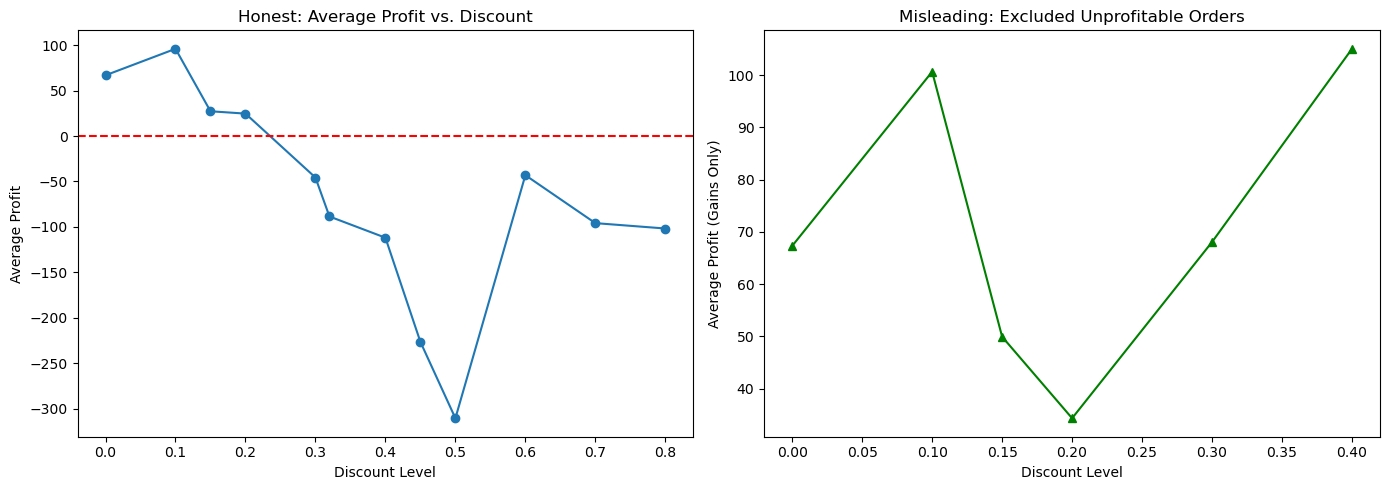

In [13]:
# Task 6 
fig6, axes6 = plt.subplots(1, 2, figsize=(14, 5))

# Honest: Avg Profit by Discount Level
disc_profit = df.groupby('Discount')['Profit'].mean().reset_index()
axes6[0].plot(disc_profit['Discount'], disc_profit['Profit'], marker='o')
axes6[0].axhline(0, color='red', linestyle='--')
axes6[0].set_title('Honest: Average Profit vs. Discount')
axes6[0].set_xlabel('Discount Level')
axes6[0].set_ylabel('Average Profit')

# Misleading: Excluded Unprofitable Orders
misleading_df = df[df['Profit'] > 0]
disc_prof_misleading = misleading_df.groupby('Discount')['Profit'].mean().reset_index()
axes6[1].plot(disc_prof_misleading['Discount'], disc_prof_misleading['Profit'], marker='^', color='green')
axes6[1].set_title('Misleading: Excluded Unprofitable Orders')
axes6[1].set_xlabel('Discount Level')
axes6[1].set_ylabel('Average Profit (Gains Only)')

plt.tight_layout()
plt.show()

### 1. Chart choice: The honest chart maps average profit against corresponding discount tiers to accurately reveal the downward correlation without hiding data. The misleading chart utilizes cherry-picking to deliberately exclude unprofitable orders (losses), manufacturing a false narrative.
### 2. Color choice & Accessibility: The honest line chart uses a high-contrast dark blue against a white background, which passes the WCAG AA 4.5:1 contrast threshold for readability. It pairs the data points with structural markers (dots) rather than relying on color alone.